<a href="https://colab.research.google.com/github/peeyush211/ML-Lab/blob/main/Missing_Values_%2C_Standardization_%2C_Normilaztion_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Missing Values , Standardization Lab 2**

**AIM3130**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load the Bengaluru house price dataset into a Pandas DataFrame
df = pd.read_csv("Bengaluru_House_Data.csv")

In [ ]:
df.head()
df.shape
df.info()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [ ]:
# Generate descriptive statistics for the numerical columns in the dataset
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


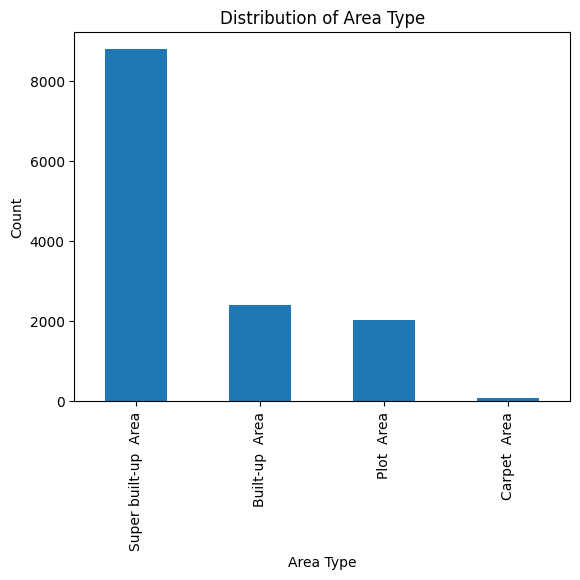

In [ ]:
# Visualize the frequency distribution of different area types
df['area_type'].value_counts().plot(kind='bar')
plt.xlabel('Area Type')
plt.ylabel('Count')
plt.title('Distribution of Area Type')
plt.show()

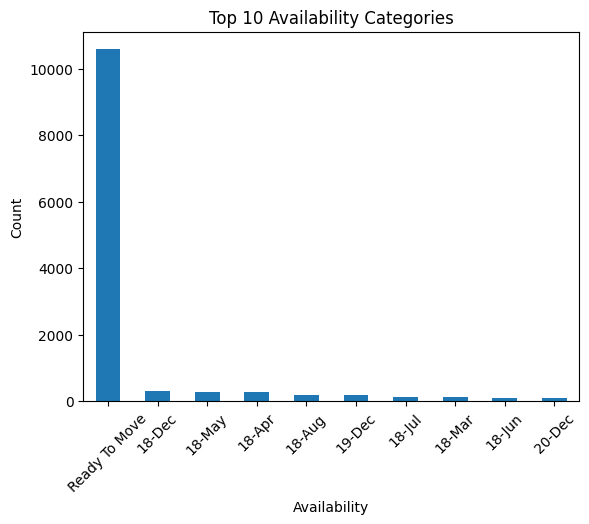

In [ ]:
# Visualize the top 10 most common property availability categories
df['availability'].value_counts().head(10).plot(kind='bar')
plt.xlabel('Availability')
plt.ylabel('Count')
plt.title('Top 10 Availability Categories')
plt.xticks(rotation=45)
plt.show()

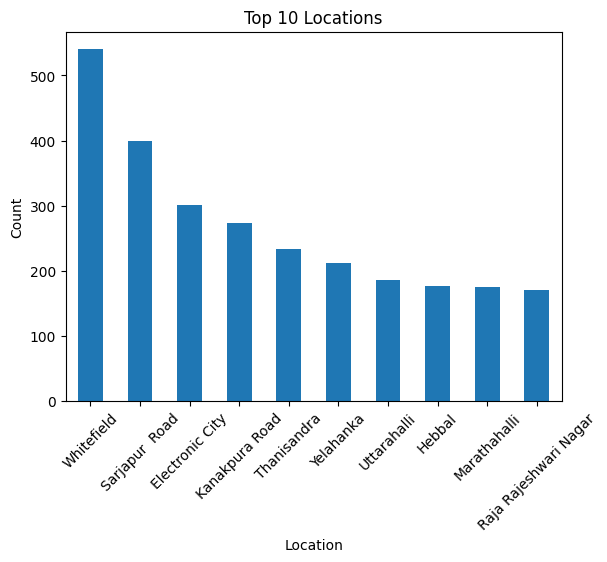

In [ ]:
# Visualize the top 10 locations with the highest number of properties
df['location'].value_counts().head(10).plot(kind='bar')
plt.xlabel('Location')
plt.ylabel('Count')
plt.title('Top 10 Locations')
plt.xticks(rotation=45)
plt.show()

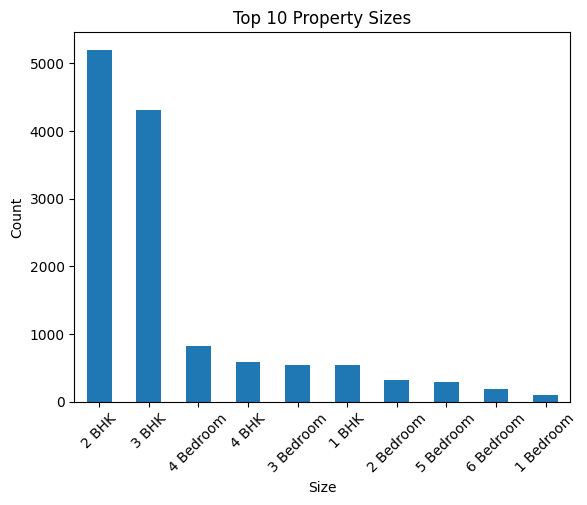

In [ ]:
df['size'].value_counts().head(10).plot(kind='bar')

plt.xlabel('Size')
plt.ylabel('Count')
plt.title('Top 10 Property Sizes')
plt.xticks(rotation=45)
plt.show()

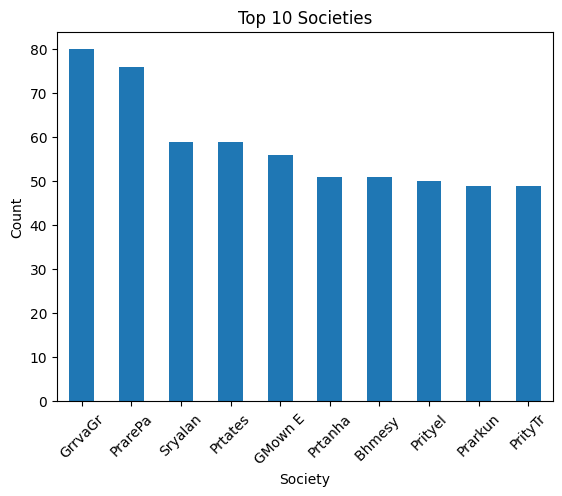

In [ ]:
df['society'].value_counts().head(10).plot(kind='bar')

plt.xlabel('Society')
plt.ylabel('Count')
plt.title('Top 10 Societies')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df.isnull().sum()

,0
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


In [ ]:
df_mean = df.copy()
df_mean['bath'] = df_mean['bath'].fillna(df_mean['bath'].mean())

In [ ]:
df_mean['bath'].isnull().sum()

np.int64(0)

In [ ]:
df_median = df.copy()
df_median['bath'] = df_median['bath'].fillna(df_median['bath'].median())
df_median['bath'].isnull().sum()

np.int64(0)

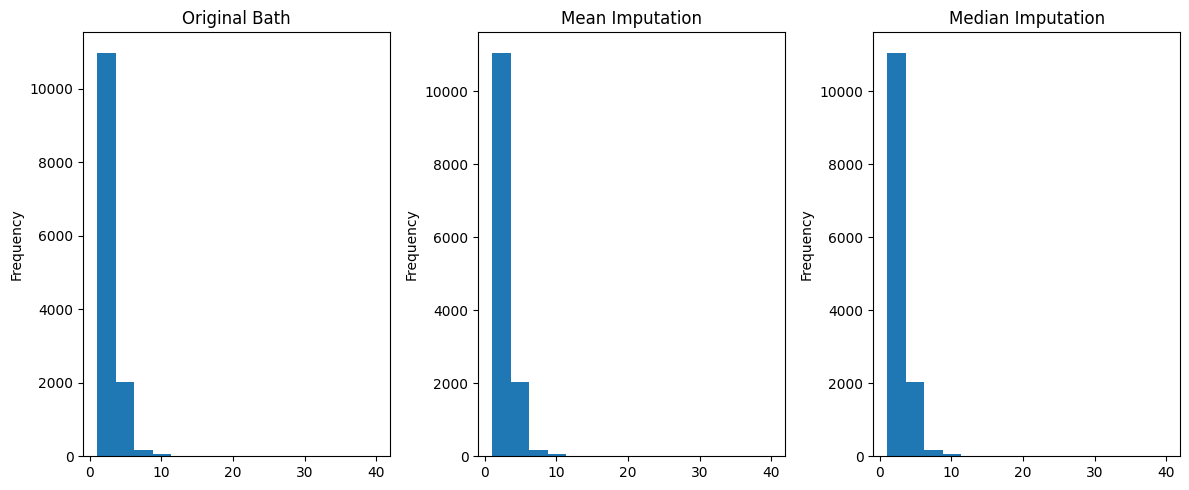

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
df['bath'].plot(kind='hist', bins=15)
plt.title('Original Bath')

plt.subplot(1, 3, 2)
df_mean['bath'].plot(kind='hist', bins=15)
plt.title('Mean Imputation')

plt.subplot(1, 3, 3)
df_median['bath'].plot(kind='hist', bins=15)
plt.title('Median Imputation')

plt.tight_layout()
plt.show()

In [ ]:
df_mode = df.copy()
df_mode['location'].mode()[0]
df_mode['location'] = df_mode['location'].fillna(df_mode['location'].mode()[0])

In [ ]:
df_mode_size = df.copy()
df_mode_size['size'] = df_mode_size['size'].fillna(
    df_mode_size['size'].mode()[0]
)

In [ ]:
df_mode_society = df.copy()

df_mode_society['society'] = df_mode_society['society'].fillna(
    df_mode_society['society'].mode()[0]
)

df_mode_society['society'].isnull().sum()

np.int64(0)

In [ ]:
df_balcony_mean = df.copy()

df_balcony_mean['balcony'] = df_balcony_mean['balcony'].fillna(
    df_balcony_mean['balcony'].mean()
)

df_balcony_mean['balcony'].isnull().sum()

np.int64(0)

In [ ]:
df_balcony_median = df.copy()

df_balcony_median['balcony'] = df_balcony_median['balcony'].fillna(
    df_balcony_median['balcony'].median()
)

df_balcony_median['balcony'].isnull().sum()

np.int64(0)

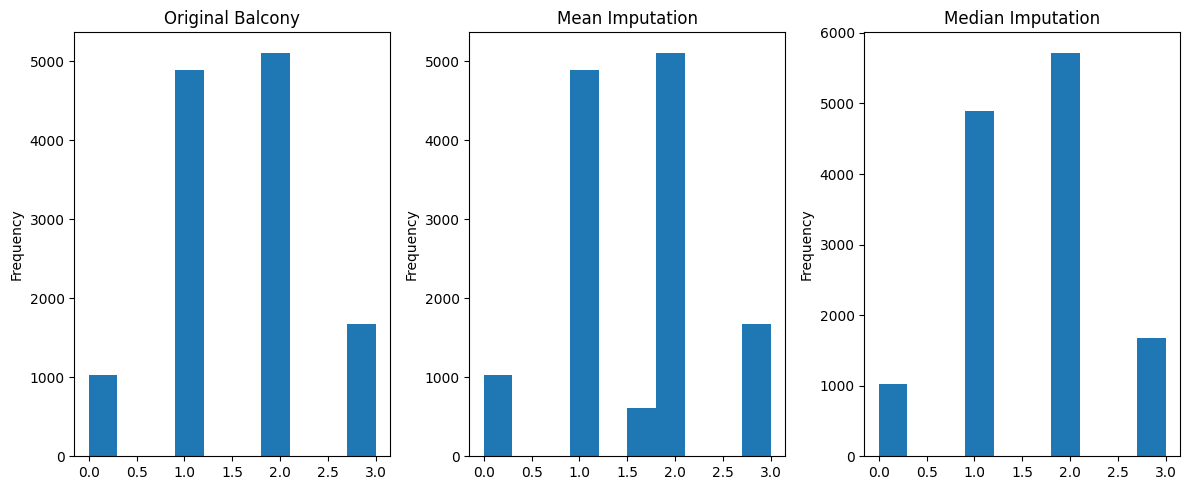

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
df['balcony'].plot(kind='hist', bins=10)
plt.title('Original Balcony')

plt.subplot(1, 3, 2)
df_balcony_mean['balcony'].plot(kind='hist', bins=10)
plt.title('Mean Imputation')

plt.subplot(1, 3, 3)
df_balcony_median['balcony'].plot(kind='hist', bins=10)
plt.title('Median Imputation')

plt.tight_layout()
plt.show()

In [ ]:
corr = df[['bath', 'balcony', 'price']].corr()
corr

,bath,balcony,price
bath,1.000000,0.204201,0.456345
balcony,0.204201,1.000000,0.120355
price,0.456345,0.120355,1.000000


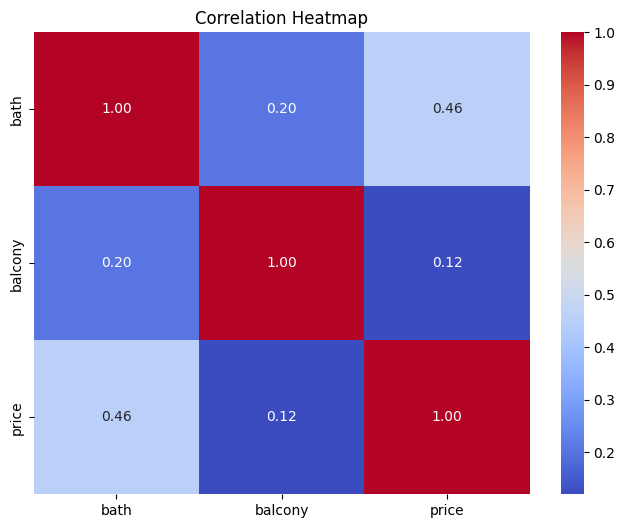

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[['bath', 'balcony', 'price']] = scaler.fit_transform(
    df_scaled[['bath', 'balcony', 'price']]
)
df_scaled[['bath', 'balcony', 'price']].head()

,bath,balcony,price
0,-0.516331,-0.715068,-0.493372
1,1.720126,1.732220,0.049906
2,-0.516331,1.732220,-0.339444
3,0.229155,-0.715068,-0.117917
4,-0.516331,-0.715068,-0.413286


In [ ]:
df_scaled[['bath', 'balcony', 'price']].describe()

,bath,balcony,price
count,1.324700e+04,1.271100e+04,1.332000e+04
mean,-1.705689e-16,-1.090047e-16,2.773891e-17
std,1.000038e+00,1.000039e+00,1.000038e+00
min,-1.261816e+00,-1.938712e+00,-7.019425e-01
25%,-5.163306e-01,-7.150678e-01,-4.199991e-01
50%,-5.163306e-01,5.085761e-01,-2.723145e-01
75%,2.291551e-01,5.085761e-01,4.990648e-02
max,2.781212e+01,1.732220e+00,2.341093e+01


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_normalized = df.copy()

df_normalized[['bath', 'balcony', 'price']] = scaler.fit_transform(
    df_normalized[['bath', 'balcony', 'price']]
)

In [ ]:
df_normalized[['bath', 'balcony', 'price']].describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,0.043400,0.528125,0.029111
std,0.034396,0.272421,0.041473
min,0.000000,0.000000,0.000000
25%,0.025641,0.333333,0.011693
50%,0.025641,0.666667,0.017817
75%,0.051282,0.666667,0.031180
max,1.000000,1.000000,1.000000
